# COU 07506 — Digital Signal Processing
## Week 4 (Lab 2A): z-Transform, Poles, Zeros and Stability

- **Name:** Ismail Mbarouk Said
- **Course:** COU 07506 — Digital Signal Processing (2026/27)
- **Environment:** Python 3, Jupyter Notebook (`COU07506-labs`)

Task 4.1 — A pole-zero plotting function

In [2]:
# Task 4.1: Pole-zero plotting function & frequency response
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w / np.pi, 20 * np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")
plt.tight_layout()
plt.show()

print("poles:", p, " stable:", np.all(np.abs(p) < 1))

NameError: name 'plt' is not defined

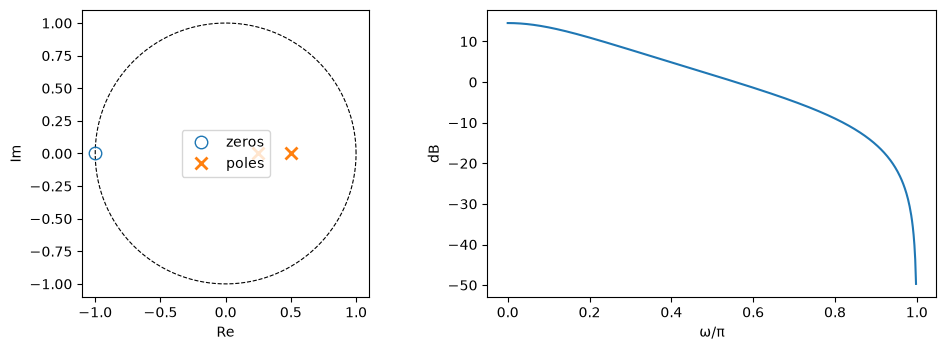

poles: [0.5  0.25]  stable: True


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Task 4.1: Pole-zero plotting function & frequency response
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w / np.pi, 20 * np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")
plt.tight_layout()
plt.show()

print("poles:", p, " stable:", np.all(np.abs(p) < 1))

Task 4.2 — Inverse z-transform with residuez

Residues (r): [-5.  6.]
Poles    (p): [0.25 0.5 ]
Direct   (k): []
Max difference (residuez vs lfilter): 0.0
Matches: True


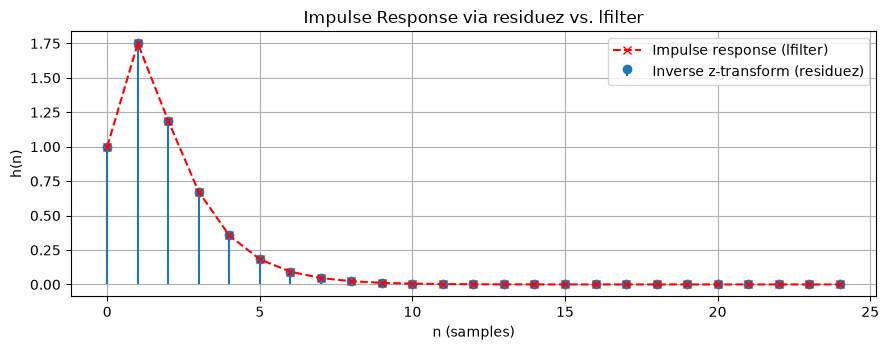

In [4]:
# Task 4.2: Inverse z-transform with residuez
b, a = [1, 1], [1, -0.75, 0.125]
r, p, k = signal.residuez(b, a)

print("Residues (r):", r)
print("Poles    (p):", p)
print("Direct   (k):", k)

n = np.arange(25)
# Causal inverse z-transform: h(n) = sum(r_i * p_i**n) + direct terms k_m * delta(n - m)
h_inv = np.zeros_like(n, dtype=float)
for ri, pi in zip(r, p):
    h_inv += np.real(ri * (pi ** n))
for m, km in enumerate(k):
    if m < len(n):
        h_inv[m] += np.real(km)

# Linganisha na impulse response kupitia lfilter
impulse = np.zeros_like(n, dtype=float)
impulse[0] = 1.0
h_lfilter = signal.lfilter(b, a, impulse)

print("Max difference (residuez vs lfilter):", np.max(np.abs(h_inv - h_lfilter)))
print("Matches:", np.allclose(h_inv, h_lfilter))

plt.figure(figsize=(9, 3.6))
plt.stem(n, h_inv, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Inverse z-transform (residuez)")
plt.plot(n, h_lfilter, "rx--", label="Impulse response (lfilter)")
plt.title("Impulse Response via residuez vs. lfilter")
plt.xlabel("n (samples)")
plt.ylabel("h(n)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [5]:
# Task 4.2 verification: b = [1, 1], a = [1, -0.75, 0.125] and h(n) = 6*(0.5)**n - 5*(0.25)**n
b_42, a_42 = [1, 1], [1, -0.75, 0.125]
r_42, p_42, k_42 = signal.residuez(b_42, a_42)

print("r (residues):", r_42)
print("p (poles):   ", p_42)
print("k (direct):  ", k_42)

n_42 = np.arange(20)
h_from_residuez = np.zeros_like(n_42, dtype=float)
for ri, pi in zip(r_42, p_42):
    h_from_residuez += np.real(ri * (pi ** n_42))
for m, km in enumerate(k_42):
    if m < len(n_42):
        h_from_residuez[m] += np.real(km)

h_target = 6.0 * (0.5 ** n_42) - 5.0 * (0.25 ** n_42)

print("Max diff vs 6*(0.5)^n - 5*(0.25)^n:", np.max(np.abs(h_from_residuez - h_target)))
print("Confirmed exact match:", np.allclose(h_from_residuez, h_target))

r (residues): [-5.  6.]
p (poles):    [0.25 0.5 ]
k (direct):   []
Max diff vs 6*(0.5)^n - 5*(0.25)^n: 0.0
Confirmed exact match: True


Task 4.3 — Pole position and the impulse response

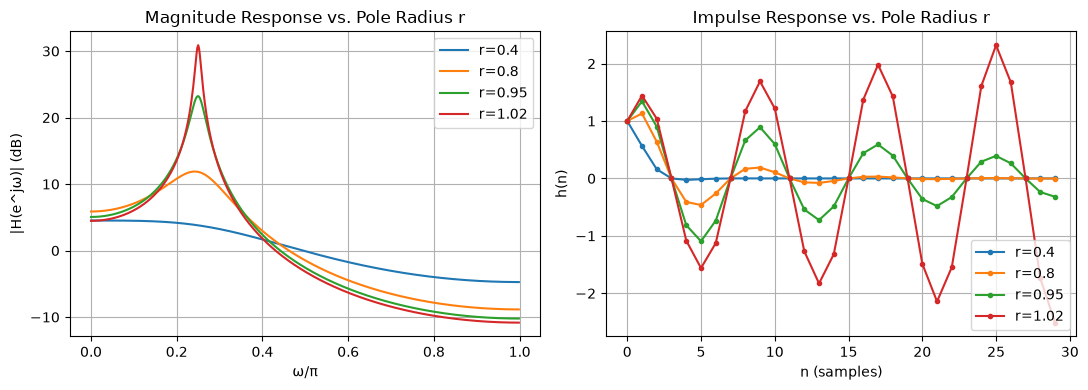

In [6]:
# Task 4.3: Pole radius, resonance, and stability
radii = [0.4, 0.8, 0.95, 1.02]
theta_0 = np.pi / 4  # resonance angle

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for r in radii:
    # Second-order resonator with complex conjugate poles at r * exp(+-j*theta_0)
    a_r = [1.0, -2.0 * r * np.cos(theta_0), r ** 2]
    b_r = [1.0]
    w_r, H_r = signal.freqz(b_r, a_r, worN=512)
    
    axes[0].plot(w_r / np.pi, 20 * np.log10(np.abs(H_r) + 1e-12), label=f"r={r}")
    
    n_r = np.arange(30)
    imp_r = np.zeros_like(n_r, dtype=float)
    imp_r[0] = 1.0
    h_r = signal.lfilter(b_r, a_r, imp_r)
    axes[1].plot(n_r, h_r, marker="o", markersize=3, label=f"r={r}")

axes[0].set_title("Magnitude Response vs. Pole Radius r")
axes[0].set_xlabel("ω/π")
axes[0].set_ylabel("|H(e^jω)| (dB)")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Impulse Response vs. Pole Radius r")
axes[1].set_xlabel("n (samples)")
axes[1].set_ylabel("h(n)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Task 4.4 — Stability of given systems 

a) H1(z)   | max|p| = 0.9434 | stable(|p|<1) = True  | |h(49)| = 3.6659e-02 | grows = False
b) H2(z)   | max|p| = 2.0000 | stable(|p|<1) = False | |h(49)| = 1.1259e+15 | grows = True
c) H3(z)   | max|p| = 1.0000 | stable(|p|<1) = False | |h(49)| = 6.6667e-01 | grows = False
d) H4(z)   | max|p| = 0.0000 | stable(|p|<1) = True  | |h(49)| = 0.0000e+00 | grows = False


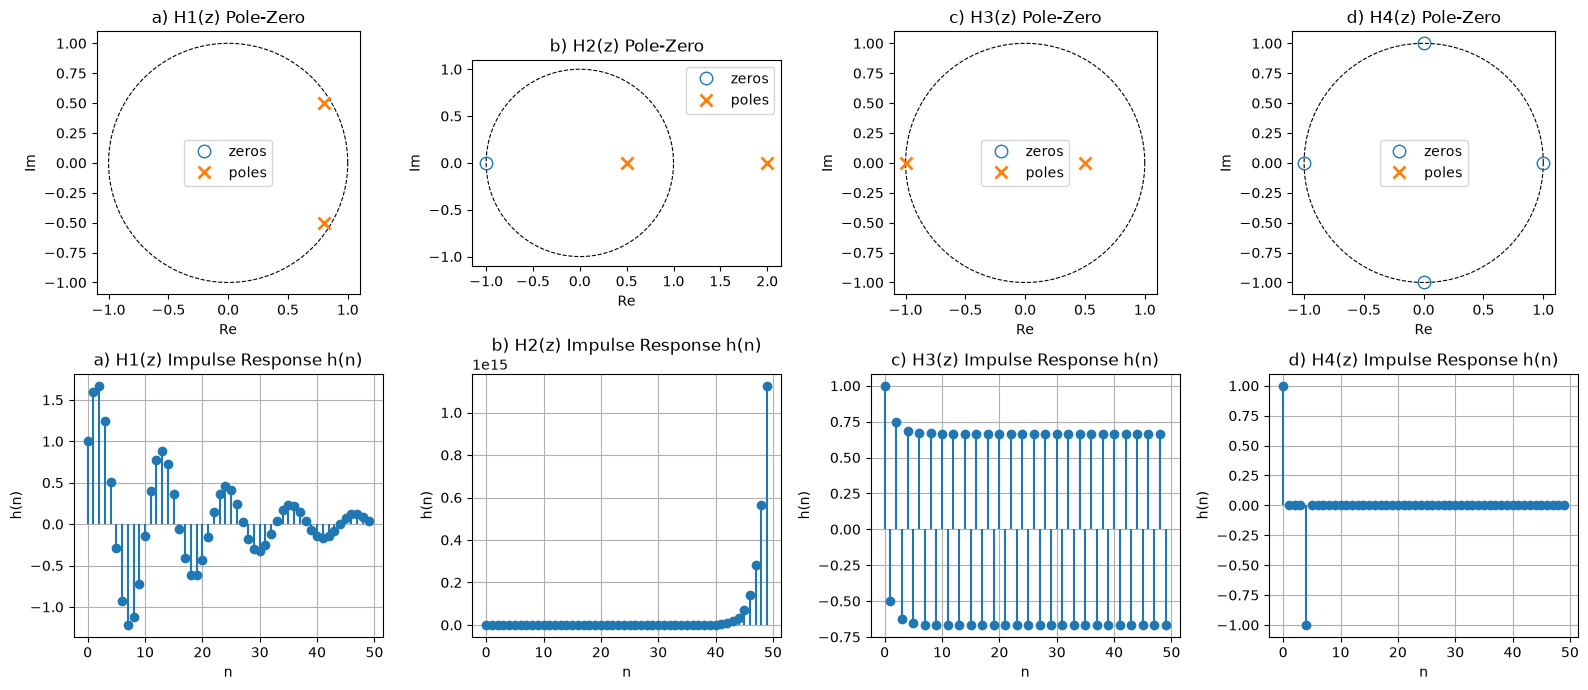

In [7]:
# Task 4.4: Stability of given systems
systems_44 = [
    ("a) H1(z)", [1.0], [1.0, -1.6, 0.89]),
    ("b) H2(z)", [1.0, 1.0], [1.0, -2.5, 1.0]),
    ("c) H3(z)", [1.0], [1.0, 0.5, -0.5]),
    ("d) H4(z)", [1.0, 0.0, 0.0, 0.0, -1.0], [1.0]),
]

n_imp = np.arange(50)
impulse_44 = np.zeros_like(n_imp, dtype=float)
impulse_44[0] = 1.0

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for col, (label, b_sys, a_sys) in enumerate(systems_44):
    ax_pz = axes[0, col]
    ax_h = axes[1, col]
    
    _, p_sys = zplane(b_sys, a_sys, ax_pz)
    ax_pz.set_title(f"{label} Pole-Zero")
    
    h_sys = signal.lfilter(b_sys, a_sys, impulse_44)
    ax_h.stem(n_imp, h_sys, linefmt="C0-", markerfmt="C0o", basefmt=" ")
    ax_h.set_title(f"{label} Impulse Response h(n)")
    ax_h.set_xlabel("n")
    ax_h.set_ylabel("h(n)")
    ax_h.grid(True)
    
    max_p_mag = np.max(np.abs(p_sys)) if len(p_sys) > 0 else 0.0
    is_stable = np.all(np.abs(p_sys) < 1.0)
    grows = np.max(np.abs(h_sys[-10:])) > np.max(np.abs(h_sys[:10])) * 1.5
    print(
        f"{label:10s} | max|p| = {max_p_mag:.4f} | stable(|p|<1) = {str(is_stable):5s} "
        f"| |h(49)| = {abs(h_sys[-1]):.4e} | grows = {grows}"
    )

plt.tight_layout()
plt.show()

Task 4.5 — Design a resonator 

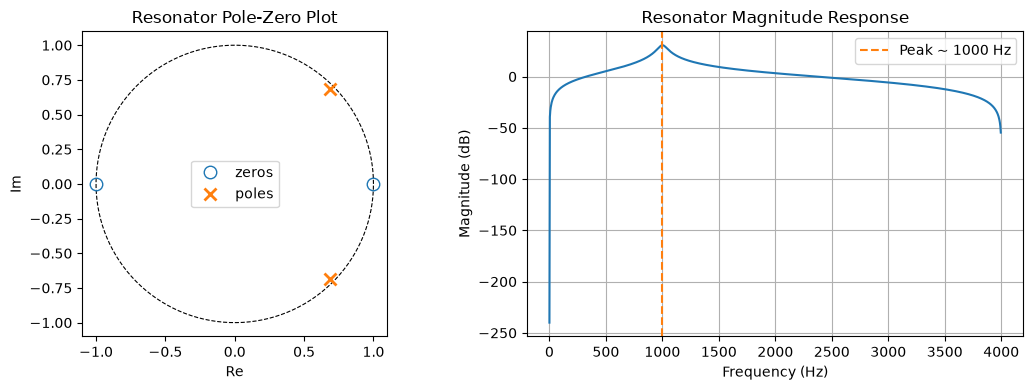

Resonator zeros: [-1.  1.]
Resonator poles: [0.6859+0.6859j 0.6859-0.6859j] | radii: [0.97 0.97]


In [8]:
from IPython.display import Audio

# Task 4.5: Design a resonator (f0 = 1 kHz, fs = 8 kHz, r = 0.97, zeros at z = +-1)
fs_res = 8000.0
f0_res = 1000.0
r_res = 0.97
w0_res = 2.0 * np.pi * f0_res / fs_res

# Denominator from complex conjugate poles at r * exp(+-j*w0)
a_res = [1.0, -2.0 * r_res * np.cos(w0_res), r_res ** 2]

# Numerator from zeros at z = +1 (DC) and z = -1 (fs/2): (1 - z^-1)(1 + z^-1) = 1 - z^-2
b_res = [1.0, 0.0, -1.0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
z_res, p_res = zplane(b_res, a_res, ax1)
ax1.set_title("Resonator Pole-Zero Plot")

w_rad, H_res = signal.freqz(b_res, a_res, worN=1024, fs=fs_res)
ax2.plot(w_rad, 20 * np.log10(np.abs(H_res) + 1e-12))
ax2.axvline(f0_res, linestyle="--", color="C1", label=f"Peak ~ {f0_res:.0f} Hz")
ax2.set_title("Resonator Magnitude Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

print("Resonator zeros:", np.round(z_res, 4))
print("Resonator poles:", np.round(p_res, 4), "| radii:", np.round(np.abs(p_res), 4))

# Apply resonator to white noise and listen
rng_res = np.random.default_rng(42)
duration_sec = 2.0
white_noise = rng_res.standard_normal(int(fs_res * duration_sec))
y_res = signal.lfilter(b_res, a_res, white_noise)
y_res = y_res / (np.max(np.abs(y_res)) + 1e-12) * 0.9

display(Audio(y_res, rate=int(fs_res)))

In [ ]:
## Pre-lab Questions (Week 4)

- **(a) Poles and stability of $H(z) = \dfrac{1}{1 - 0.9z^{-1} + 0.81z^{-2}}$:**  
  Multiplying numerator and denominator by $z^2$ gives:
  $$H(z) = \frac{z^2}{z^2 - 0.9z + 0.81}$$
  Solving $z^2 - 0.9z + 0.81 = 0$:
  $$z = \frac{0.9 \pm \sqrt{(-0.9)^2 - 4(1)(0.81)}}{2} = \frac{0.9 \pm \sqrt{0.81 - 3.24}}{2} = \frac{0.9 \pm j\sqrt{2.43}}{2} \approx 0.45 \pm j0.7794$$
  The pole magnitude (radius) is:
  $$|p| = \sqrt{0.45^2 + 0.7794^2} = \sqrt{0.81} = 0.9$$
  Since $|p| = 0.9 < 1$ (poles lie strictly inside the unit circle), the causal system is **stable**.

- **(b) Partial-fraction expansion of $X(z) = \dfrac{1}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})}$:**  
  Assume:
  $$\frac{1}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})} = \frac{A}{1 - 0.5z^{-1}} + \frac{B}{1 - 0.25z^{-1}}$$
  Using cover-up / residue evaluation:
  - At $z^{-1} = 2$ (i.e., $1 - 0.5z^{-1} = 0$):
    $$A = \left.\frac{1}{1 - 0.25z^{-1}}\right|_{z^{-1} = 2} = \frac{1}{1 - 0.25(2)} = \frac{1}{0.5} = 2$$
  - At $z^{-1} = 4$ (i.e., $1 - 0.25z^{-1} = 0$):
    $$B = \left.\frac{1}{1 - 0.5z^{-1}}\right|_{z^{-1} = 4} = \frac{1}{1 - 0.5(4)} = \frac{1}{-1} = -1$$
  Therefore:
  $$X(z) = \frac{2}{1 - 0.5z^{-1}} - \frac{1}{1 - 0.25z^{-1}}$$

---

## Analysis Questions (Week 4)

1. **Effect of $r$ on the bandwidth of the resonance in Task 4.3:**  
   As the pole radius $r$ approaches $1$ from inside the unit circle ($r \to 1^-$), the poles move closer to the unit circle and the resonance peak becomes sharper and **narrower** (smaller bandwidth, higher quality factor $Q$). Conversely, as $r$ decreases away from $1$, the peak broadens and flattens (**wider** bandwidth and lower resonance gain).

2. **What happens to $h(n)$ when a pole lies exactly on the unit circle:**  
   When a pole lies right on the unit circle ($|p| = 1$), its mode neither decays exponentially toward zero nor grows exponentially without bound—instead, $h(n)$ **persists indefinitely** with constant amplitude (for a simple pole on the unit circle: a constant step/DC level if at $z = +1$, alternating $\pm 1$ if at $z = -1$, or a sustained sinusoid for complex conjugate poles on the unit circle). Because $h(n)$ does not decay to zero ($h(n) \not\to 0$ as $n \to \infty$), the system is marginally stable / not strictly BIBO stable.

3. **Why placing zeros at $z = \pm 1$ makes the resonator a band-pass filter:**  
   A zero at $z = +1$ ($\omega = 0$) nulls or strongly attenuates low frequencies near DC, while a zero at $z = -1$ ($\omega = \pi$, corresponding to $f_s / 2$) nulls or strongly attenuates high frequencies near Nyquist. Combined with the resonant pole pair near the target passband frequency $\omega_0$, both the very low and very high frequency ends are suppressed while frequencies around $\omega_0$ are passed—forming a **band-pass** response.

4. **Stability triangle check for Task 4.4 (a)–(c) (for $A(z) = 1 + a_1 z^{-1} + a_2 z^{-2}$):**  
   A second-order polynomial $1 + a_1 z^{-1} + a_2 z^{-2}$ has both roots strictly inside the unit circle iff:
   $$|a_2| < 1, \qquad a_1 + a_2 > -1, \qquad a_2 - a_1 > -1$$
   - **(a) $H_1(z)$ ($a_1 = -1.6,\ a_2 = 0.89$):** $|0.89| = 0.89 < 1$; $-1.6 + 0.89 = -0.71 > -1$; $0.89 - (-1.6) = 2.49 > -1$. All conditions hold $\implies$ **Stable** (matches Task 4.4(a)).
   - **(b) $H_2(z)$ ($a_1 = -2.5,\ a_2 = 1.0$):** $|a_2| = 1.0$ (not $< 1$) and $-2.5 + 1.0 = -1.5 \not> -1$ (violates triangle conditions) $\implies$ **Unstable** (matches Task 4.4(b)).
   - **(c) $H_3(z)$ ($a_1 = 0.5,\ a_2 = -0.5$):** $|-0.5| = 0.5 < 1$; $0.5 + (-0.5) = 0 > -1$; however, $-0.5 - 0.5 = -1.0$ lies **on** the boundary line rather than strictly $> -1$ (corresponding to a root at $z = -1$ on the unit circle) $\implies$ **On stability boundary / not strictly stable** (matches Task 4.4(c)).